<a href="https://colab.research.google.com/github/mhage82/ARI510/blob/main/lab3_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ARI 410/510 Lab 3 Starter Notebook

This notebook gives you the building blocks: downloading the data, viewing a meme, and two pretrained **encoders** (BERT for text, ResNet-18 for images) that turn each meme into vectors. Building, training, and comparing the classifiers is up to you (see the assignment PDF).

**Content note:** this dataset contains hateful and offensive content.

**How to use this:** in Colab, *File → Save a copy in Drive*, and switch to a GPU runtime (*Runtime → Change runtime type*). Run everything on a small subset first (section 5).

> ### ⚠️ Compute your embeddings once, then stop using the images
> The dataset is about 3 GB, and running BERT and ResNet over it is the slowest part of this lab. **You should only do it once.** Section 5 saves your embeddings to your Google Drive. After that, every new Colab session should start at **section 6**, which loads the saved embeddings in a few seconds. No download, no GPU needed.
>
> The only reason to download the images again is to *look at* memes (Part 0, and the 410 "look at the memes" analysis).

## 0. Get the data

The dataset is stored with Git LFS, so this download takes a few minutes. Colab deletes files when your session ends, so this download disappears too.

**If you have already saved your full embeddings (section 5), skip to section 6 instead.** You only need to rerun this cell if you want to look at the images again.

In [5]:
# OLD VERSION
#!git lfs install
#!git clone https://huggingface.co/datasets/neuralcatcher/hateful_memes

# RECOMMENDED UPDATE
!pip install -q huggingface_hub

from huggingface_hub import snapshot_download

snapshot_download(
    repo_id="cs5242-hateful-memes/hateful-memes-data",
    repo_type="dataset",
    local_dir="hateful_memes",
    ignore_patterns=["data/**"],
)


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
c:\Users\moham\workspace\21_ML\ARI510\repo\ARI510\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 10008 files: 100%|██████████| 10008/10008 [00:22<00:00, 440.25it/s]


'C:\\Users\\moham\\workspace\\21_ML\\ARI510\\repo\\ARI510\\notebooks\\hateful_memes'

## 1. Load the splits

In [6]:
import os
import pandas as pd

DATA = "hateful_memes"   # folder created by the git clone above
print(sorted(f for f in os.listdir(DATA) if f.endswith(".jsonl")))

def load_split(name):
    df = pd.read_json(os.path.join(DATA, name), lines=True)
    df["path"] = df["img"].apply(lambda p: os.path.join(DATA, p))
    return df

train = load_split("train.jsonl")
dev   = load_split("dev_seen.jsonl")
test  = load_split("test_seen.jsonl")

for name, df in [("train", train), ("dev", dev), ("test", test)]:
    print(f"{name}: {len(df)} memes, {df['label'].mean():.1%} hateful")

train.head()

['dev_seen.jsonl', 'dev_unseen.jsonl', 'test_seen.jsonl', 'test_unseen.jsonl', 'train.jsonl']
train: 8500 memes, 35.5% hateful
dev: 500 memes, 49.4% hateful
test: 1000 memes, 49.0% hateful


,id,img,label,text,path
0,42953,img/42953.png,0,its their character not their color that matters,hateful_memes\img/42953.png
1,23058,img/23058.png,0,don't be afraid to love again everyone is not ...,hateful_memes\img/23058.png
2,13894,img/13894.png,0,putting bows on your pet,hateful_memes\img/13894.png
3,37408,img/37408.png,0,i love everything and everybody! except for sq...,hateful_memes\img/37408.png
4,82403,img/82403.png,0,"everybody loves chocolate chip cookies, even h...",hateful_memes\img/82403.png


## 2. Look at a meme

`show_meme` displays a meme's image with its text and label. Use it for Part 0 of the assignment, and later to look at examples your models get right and wrong.

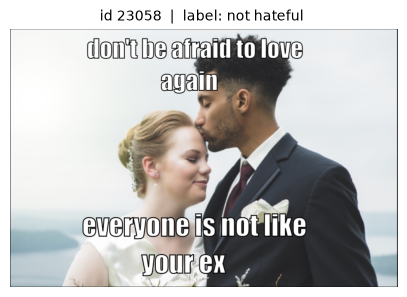

Text: don't be afraid to love again everyone is not like your ex


In [7]:
import matplotlib.pyplot as plt
from PIL import Image

def show_meme(row, note=""):
    """Display one meme. `row` is a row of a split, e.g. dev.iloc[0]."""
    img = Image.open(row["path"]).convert("RGB")
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    label = {0: "not hateful", 1: "hateful"}.get(row.get("label"), "unknown")
    plt.title(f"id {row['id']}  |  label: {label} {note}", fontsize=10)
    plt.show()
    print("Text:", row["text"])

show_meme(train.iloc[1])

## 3. Where embeddings get saved

Computing embeddings is the slow part of this lab. This cell mounts Google Drive so they are saved there and survive the end of your Colab session.

In [8]:
%pip install torch==2.11.0 torchvision==0.26.0 --index-url https://download.pytorch.org/whl/cu128
%pip install transformers

import torch

try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/lab3_embeddings"
except ImportError:   # running locally instead of in Colab
    SAVE_DIR = "lab3_embeddings"
os.makedirs(SAVE_DIR, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using", device, "| saving to", SAVE_DIR)

def get_embeddings(name, compute_fn):
    """Load saved embeddings called `name` if they exist; otherwise compute and save them."""
    path = os.path.join(SAVE_DIR, name + ".pt")
    if os.path.exists(path):
        print("loaded", path)
        return torch.load(path)
    emb = compute_fn()
    torch.save(emb, path)
    print("saved", path, tuple(emb.shape))
    return emb

Looking in indexes: https://download.pytorch.org/whl/cu128
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Using cuda | saving to lab3_embeddings


## 4. The pretrained encoders

Neither model below has ever been trained on memes or on hate speech. BERT was trained to predict missing words in books and Wikipedia; ResNet-18 was trained to sort photos into 1,000 ImageNet categories (dogs, cars, mushrooms, ...). We use them **as-is** (no training, `eval()` mode, no gradients) and keep an internal vector instead of their usual output. Your classifiers then learn from those vectors.

### Text: BERT
We keep BERT's vector for the special `[CLS]` token: **768 numbers per text**.

In [10]:
from transformers import AutoTokenizer, AutoModel

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModel.from_pretrained("bert-base-uncased").to(device).eval()

def embed_texts(texts, batch_size=32):
    """List of strings -> tensor of shape [len(texts), 768]."""
    out = []
    for i in range(0, len(texts), batch_size):
        inputs = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                           max_length=128, return_tensors="pt").to(device)
        with torch.no_grad():
            out.append(bert(**inputs).last_hidden_state[:, 0, :].cpu())
    return torch.cat(out)

print(embed_texts(train["text"].head(4).tolist()).shape)   # expect [4, 768]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 772.58it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


torch.Size([4, 768])


### Images: ResNet-18
ResNet-18's last layer turns a 512-number vector into scores for the 1,000 ImageNet categories. We replace that layer with `Identity()` (a layer that does nothing), so the model outputs the **512-number vector** instead. Each set of pretrained weights comes with the image preprocessing it expects (resizing, cropping, normalizing), which we apply to every image.

In [11]:
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.DEFAULT
resnet = resnet18(weights=weights)
resnet.fc = torch.nn.Identity()          # remove the final classification layer
resnet = resnet.to(device).eval()
preprocess = weights.transforms()         # the preprocessing these weights expect

def embed_images(paths, batch_size=64):
    """List of image paths -> tensor of shape [len(paths), 512]."""
    out = []
    for i in range(0, len(paths), batch_size):
        # .convert("RGB") handles PNGs with a transparency channel
        batch = torch.stack([preprocess(Image.open(p).convert("RGB"))
                             for p in paths[i:i + batch_size]]).to(device)
        with torch.no_grad():
            out.append(resnet(batch).cpu())
    return torch.cat(out)

print(embed_images(train["path"].head(4).tolist()).shape)   # expect [4, 512]

torch.Size([4, 512])


## 5. Compute and save all the embeddings (once!)

Start with `SUBSET = 200` to make sure everything works end to end. Then set `SUBSET = None` and rerun to embed everything (the image step for the training set takes the longest; a few minutes on a GPU). Because of `get_embeddings`, anything already saved is loaded instead of recomputed.

Note: the file names include the subset size, so subset and full runs don't overwrite each other. This cell also saves each split's ids, texts, and labels as a small CSV, so you can work without the original data files later.

In [12]:
SUBSET = None   # set to None for the full dataset

splits = {"train": train, "dev": dev, "test": test}
if SUBSET is not None:
    splits = {name: df.head(SUBSET) for name, df in splits.items()}
tag = "all" if SUBSET is None else str(SUBSET)

X_text, X_image, y = {}, {}, {}
for name, df in splits.items():
    X_text[name]  = get_embeddings(f"{name}_text_{tag}",  lambda: embed_texts(df["text"].tolist()))
    X_image[name] = get_embeddings(f"{name}_image_{tag}", lambda: embed_images(df["path"].tolist()))
    y[name] = torch.tensor(df["label"].values)
    df[["id", "text", "label"]].to_csv(os.path.join(SAVE_DIR, f"{name}_meta_{tag}.csv"), index=False)

for name in splits:
    print(name, tuple(X_text[name].shape), tuple(X_image[name].shape), tuple(y[name].shape))
print("Saved to", SAVE_DIR, ":", sorted(os.listdir(SAVE_DIR)))

loaded lab3_embeddings\train_text_all.pt
loaded lab3_embeddings\train_image_all.pt
loaded lab3_embeddings\dev_text_all.pt
loaded lab3_embeddings\dev_image_all.pt
loaded lab3_embeddings\test_text_all.pt
loaded lab3_embeddings\test_image_all.pt
train (8500, 768) (8500, 512) (8500,)
dev (500, 768) (500, 512) (500,)
test (1000, 768) (1000, 512) (1000,)
Saved to lab3_embeddings : ['dev_image_200.pt', 'dev_image_all.pt', 'dev_meta_200.csv', 'dev_meta_all.csv', 'dev_text_200.pt', 'dev_text_all.pt', 'early_fusion_classifier.pt', 'fusion_settings.json', 'image_classifier.pt', 'test_image_200.pt', 'test_image_all.pt', 'test_meta_200.csv', 'test_meta_all.csv', 'test_text_200.pt', 'test_text_all.pt', 'text_classifier.pt', 'train_image_200.pt', 'train_image_all.pt', 'train_meta_200.csv', 'train_meta_all.csv', 'train_text_200.pt', 'train_text_all.pt']


Once this has run with `SUBSET = None`, check that the files above are in your Google Drive. **From now on, you never need to recompute them.**

## 6. Starting a new session? Load your saved embeddings here

Once section 5 has run on the full dataset, start every new Colab session **here** instead of at the top. This cell only reads the files saved in your Google Drive: no dataset download, no BERT or ResNet, and no GPU needed.

In [13]:
import os, torch, pandas as pd

try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/lab3_embeddings"
except ImportError:
    SAVE_DIR = "lab3_embeddings"

tag = "all"   # use "200" to load the subset instead
X_text, X_image, y, meta = {}, {}, {}, {}
for name in ["train", "dev", "test"]:
    X_text[name]  = torch.load(os.path.join(SAVE_DIR, f"{name}_text_{tag}.pt"))
    X_image[name] = torch.load(os.path.join(SAVE_DIR, f"{name}_image_{tag}.pt"))
    meta[name]    = pd.read_csv(os.path.join(SAVE_DIR, f"{name}_meta_{tag}.csv"))   # id, text, label
    y[name] = torch.tensor(meta[name]["label"].values)
    print(name, tuple(X_text[name].shape), tuple(X_image[name].shape), tuple(y[name].shape))

train (8500, 768) (8500, 512) (8500,)
dev (500, 768) (500, 512) (500,)
test (1000, 768) (1000, 512) (1000,)


## 7. Your turn

You now have, for each split (`"train"`, `"dev"`, `"test"`):
- `X_text[split]`: BERT vectors, shape `[n, 768]`
- `X_image[split]`: ResNet vectors, shape `[n, 512]`
- `y[split]`: labels (1 = hateful, 0 = not hateful)

The rows line up: row *i* of each tensor is the same meme (and, if you loaded from section 6, the same row of `meta[split]`, so you can look up a meme's id and text). Next steps (see the assignment for details): build the classifier, run the sanity checks, train text-only and image-only models, then early and late fusion, and compare.

Keep your work log going as you work (see the Reflection section of the assignment).

### Look at some training memes

In [3]:
# for i in range(15):
#     show_meme(train.iloc[i])

### label some dev memes


 Meme 1 of 20 with ID 87520


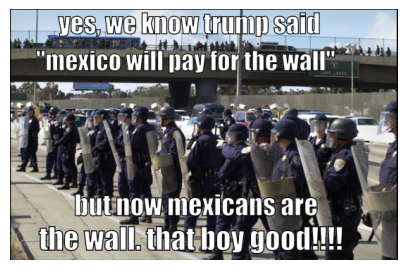

Text: yes, we know trump said "mexico will pay for the wall" but now mexicans are the wall. that boy good!!!!

 Meme 2 of 20 with ID 56207


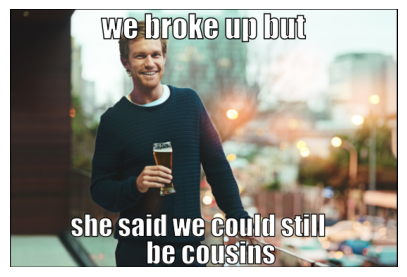

Text: we broke up but she said we could still be cousins

 Meme 3 of 20 with ID 73482


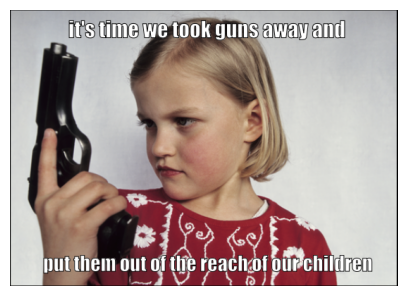

Text: it's time we took guns away and put them out of the reach of our children

 Meme 4 of 20 with ID 94185


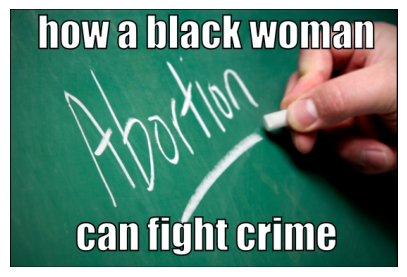

Text: how a black woman can fight crime

 Meme 5 of 20 with ID 18945


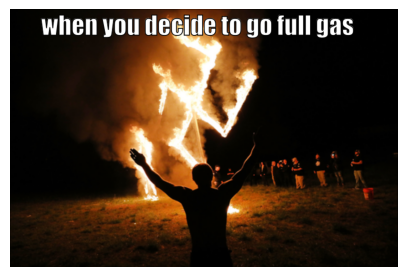

Text: when you decide to go full gas

 Meme 6 of 20 with ID 63827


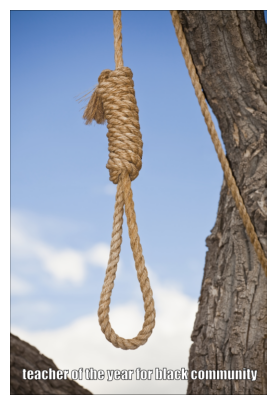

Text: teacher of the year for black community

 Meme 7 of 20 with ID 89425


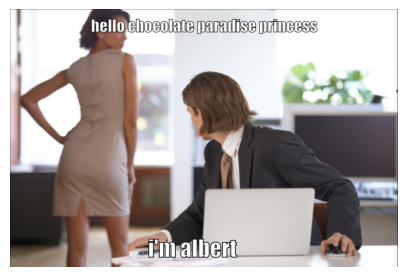

Text: hello chocolate paradise princess i'm albert

 Meme 8 of 20 with ID 68401


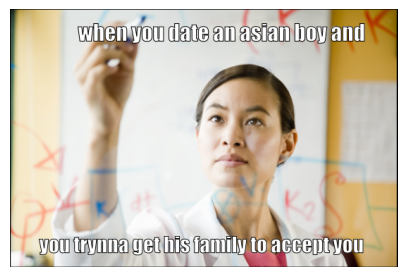

Text: when you date an asian boy and you trynna get his family to accept you

 Meme 9 of 20 with ID 38076


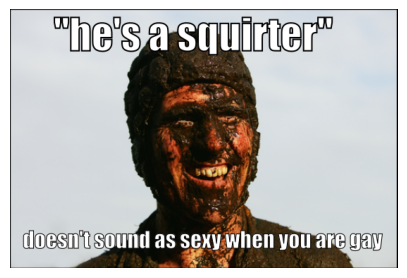

Text: "he's a squirter" doesn't sound as sexy when you are gay

 Meme 10 of 20 with ID 94813


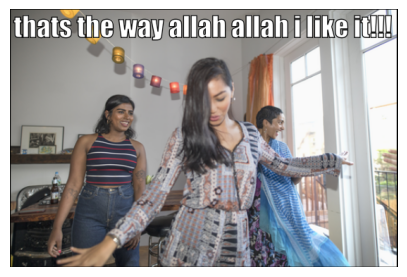

Text: thats the way allah allah i like it!!!

 Meme 11 of 20 with ID 50198


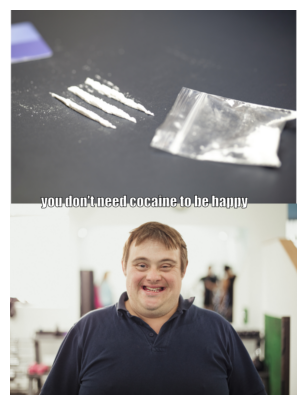

Text: you don't need cocaine to be happy

 Meme 12 of 20 with ID 89642


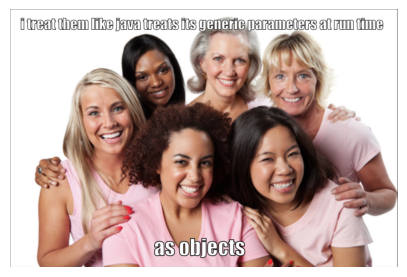

Text: i treat them like java treats its generic parameters at run time as objects

 Meme 13 of 20 with ID 47103


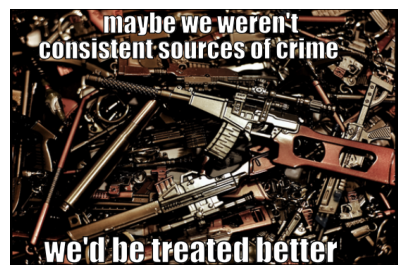

Text: maybe we weren't consistent sources of crime we'd be treated better

 Meme 14 of 20 with ID 41058


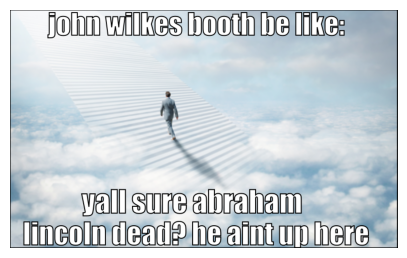

Text: john wilkes booth be like: yall sure abraham lincoln dead? he aint up here

 Meme 15 of 20 with ID 95038


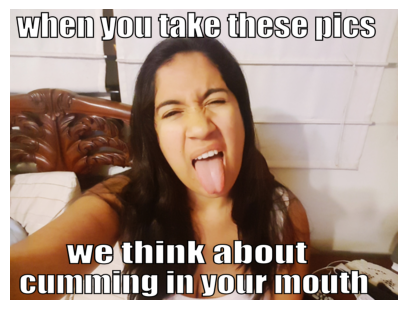

Text: when you take these pics we think about cumming in your mouth

 Meme 16 of 20 with ID 83264


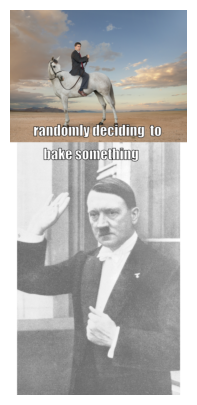

Text: randomly deciding to bake something

 Meme 17 of 20 with ID 73021


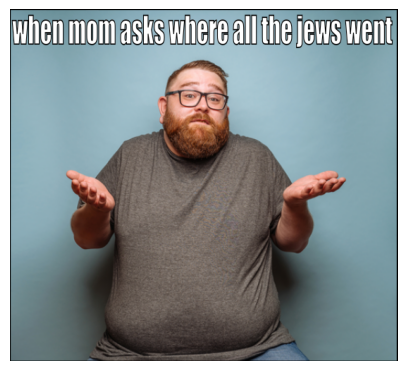

Text: when mom asks where all the jews went

 Meme 18 of 20 with ID 64125


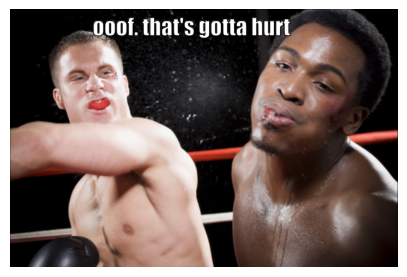

Text: ooof. that's gotta hurt

 Meme 19 of 20 with ID 62504


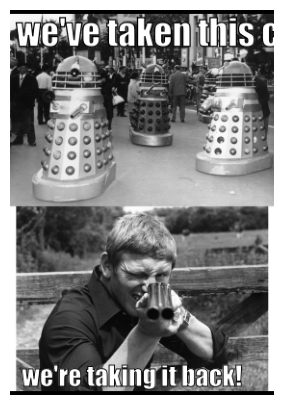

Text: we've taken this country! now fuck off! we're taking it back!

 Meme 20 of 20 with ID 78659


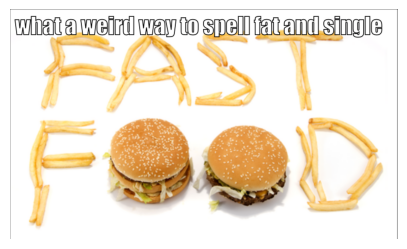

Text: what a weird way to spell fat and single

 All the guesses are recorded



In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

my_sample = dev.sample(n=20, random_state = 43)
my_guesses = []

for number, (_, row) in enumerate(my_sample.iterrows(), start=1):
    print(f"\n Meme {number} of 20 with ID {row['id']}")

    image = Image.open(row["path"]).convert("RGB")
    plt.figure(figsize=(5,5))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

    print("Text:", row["text"])

    guess = input("Your guess (0= not hateful, 1 = hateful):").strip()
    while(guess not in ("0", "1")):
            guess = input("please enter 0 or 1:").strip()

    my_guesses.append(int(guess))

print("\n All the guesses are recorded\n")


### compare against real results

In [15]:
results = my_sample[["id", "text", "label"]].copy()
results["my_guess"] = my_guesses
results["correct"] = results["my_guess"] == results["label"]

accuracy = results["correct"].mean()
print(f"Your accuracy: {accuracy:.1%}")
print(f"Correct: {results['correct'].sum()} out of {len(results)}")

display(results[["id", "my_guess", "label", "correct"]])

Your accuracy: 45.0%
Correct: 9 out of 20


,id,my_guess,label,correct
17,87520,1,1,True
127,56207,1,1,True
363,73482,1,0,False
82,94185,1,1,True
60,18945,1,1,True
251,63827,1,1,True
258,89425,1,1,True
339,68401,1,0,False
208,38076,1,1,True
67,94813,1,0,False


In [15]:
results.to_csv("human_baseline_results.csv", index=False)

### Step 3-1 Compute all metrics on the dev set for a “model” that always predicts not hateful.

In [16]:
import torch
# Formalize it so this format could be used the same way as we measure actual results.
dev_labels = y["dev"].int()
simple_pred = torch.zeros_like(dev_labels)

tp = ((simple_pred == 1) & (dev_labels == 1)).sum().item()
fp = ((simple_pred == 1) & (dev_labels == 0)).sum().item()
fn = ((simple_pred == 0) & (dev_labels == 1)).sum().item()
tp,fp,fn

accuracy = (simple_pred == dev_labels).float().mean().item()
precision = tp / (tp + fp) if (tp + fp) else 0.0
recall = tp / (tp + fn) if (tp + fn) else 0.0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0

print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1:        {f1:.3f}")

Accuracy:  0.506
Precision: 0.000
Recall:    0.000
F1:        0.000


### Step 3-2 compute the loss on a batch

In [17]:
import torch
import torch.nn as nn
torch.manual_seed(42)

text_model = nn.Sequential(
    nn.Linear(768, 128), # 128 hidden values
    nn.ReLU(),
    nn.Linear(128,1)
)

print(text_model)

text_batch = X_text["train"][:64].float()
labels_batch = y["train"][:64].float().unsqueeze(1)

with torch.no_grad():
    logits = text_model(text_batch)
    initial_loss = nn.BCEWithLogitsLoss()(logits, labels_batch)

print("initial loss is ", initial_loss.item())


Sequential(
  (0): Linear(in_features=768, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=1, bias=True)
)
initial loss is  0.6954808831214905


### Step 3-3 Train on a batch

In [18]:
tiny_text = X_text["train"][:20].float()
tiny_labels = y["train"][:20].float().unsqueeze(1)

print("Text shape:", tiny_text.shape)
print("Label shape:", tiny_labels.shape)
print("Hateful examples:", int(tiny_labels.sum().item()))

torch.manual_seed(42)

tiny_model = nn.Sequential(
    nn.Linear(768, 128),
    nn.ReLU(),
    nn.Linear(128, 1)
)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(tiny_model.parameters(), lr=0.001)

for epoch in range(300):
    tiny_model.train()

    # Calculate the loss on the 20 examples.
    logits = tiny_model(tiny_text)
    loss = criterion(logits, tiny_labels)

    # Update the model's weights.
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Check progress after the weight update.
    if (epoch + 1) % 20 == 0 or epoch == 0:
        tiny_model.eval()
        with torch.no_grad():
            current_logits = tiny_model(tiny_text)
            current_loss = criterion(current_logits, tiny_labels)

            probabilities = torch.sigmoid(current_logits)
            predictions = (probabilities >= 0.5).float()
            accuracy = (predictions == tiny_labels).float().mean()

        print(
            f"Epoch {epoch + 1:3d} | "
            f"Loss: {current_loss.item():.4f} | "
            f"Accuracy: {accuracy.item():.1%}"
        )

Text shape: torch.Size([20, 768])
Label shape: torch.Size([20, 1])
Hateful examples: 3
Epoch   1 | Loss: 0.5625 | Accuracy: 85.0%
Epoch  20 | Loss: 0.1966 | Accuracy: 95.0%
Epoch  40 | Loss: 0.0471 | Accuracy: 100.0%
Epoch  60 | Loss: 0.0131 | Accuracy: 100.0%
Epoch  80 | Loss: 0.0061 | Accuracy: 100.0%
Epoch 100 | Loss: 0.0038 | Accuracy: 100.0%
Epoch 120 | Loss: 0.0027 | Accuracy: 100.0%
Epoch 140 | Loss: 0.0020 | Accuracy: 100.0%
Epoch 160 | Loss: 0.0016 | Accuracy: 100.0%
Epoch 180 | Loss: 0.0013 | Accuracy: 100.0%
Epoch 200 | Loss: 0.0011 | Accuracy: 100.0%
Epoch 220 | Loss: 0.0009 | Accuracy: 100.0%
Epoch 240 | Loss: 0.0008 | Accuracy: 100.0%
Epoch 260 | Loss: 0.0007 | Accuracy: 100.0%
Epoch 280 | Loss: 0.0006 | Accuracy: 100.0%
Epoch 300 | Loss: 0.0005 | Accuracy: 100.0%


### Step 3-4 Train on the full set

In [19]:
import copy
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def train_classifier(train_X, train_y, dev_X, dev_y,
                     hidden_dim=128, epochs=15, learning_rate=0.001):

    # Create a fresh classifier. The number of inputs comes from the vectors.
    torch.manual_seed(42)
    model = nn.Sequential(
        nn.Linear(train_X.shape[1], hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, 1)
    )

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    # Prepare batches of training examples.
    train_dataset = TensorDataset(
        train_X.float(),
        train_y.float().unsqueeze(1)
    )
    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

    dev_X = dev_X.float()
    dev_labels = dev_y.float().unsqueeze(1)

    train_losses = []
    dev_losses = []
    best_dev_loss = float("inf")
    best_weights = None
    best_epoch = 0

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            logits = model(batch_X)
            loss = criterion(logits, batch_y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(batch_X)

        # Average loss across the training examples.
        train_loss = total_loss / len(train_dataset)

        # Measure dev loss without updating the model.
        model.eval()
        with torch.no_grad():
            dev_logits = model(dev_X)
            dev_loss = criterion(dev_logits, dev_labels).item()

        train_losses.append(train_loss)
        dev_losses.append(dev_loss)

        # Keep the weights from the epoch with the lowest dev loss.
        if dev_loss < best_dev_loss:
            best_dev_loss = dev_loss
            best_weights = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1

        print(
            f"Epoch {epoch + 1:2d} | "
            f"Train loss: {train_loss:.4f} | "
            f"Dev loss: {dev_loss:.4f}"
        )

    # Restore the best-performing epoch on the dev set.
    model.load_state_dict(best_weights)
    model.eval()

    with torch.no_grad():
        probabilities = torch.sigmoid(model(dev_X)).squeeze(1)
        predictions = (probabilities >= 0.5).int()

    metrics = {
        "accuracy": accuracy_score(dev_y.cpu(), predictions.cpu()),
        "precision": precision_score(dev_y.cpu(), predictions.cpu(), zero_division=0),
        "recall": recall_score(dev_y.cpu(), predictions.cpu(), zero_division=0),
        "f1": f1_score(dev_y.cpu(), predictions.cpu(), zero_division=0),
    }

    return model, metrics, train_losses, dev_losses, best_epoch

In [20]:
text_model, text_metrics, text_train_losses, text_dev_losses, text_best_epoch = (
    train_classifier(
        X_text["train"], y["train"],
        X_text["dev"], y["dev"]
    )
)

print("\nBest epoch:", text_best_epoch)
print("Dev metrics:", text_metrics)

Epoch  1 | Train loss: 0.5916 | Dev loss: 0.7399
Epoch  2 | Train loss: 0.5527 | Dev loss: 0.7044
Epoch  3 | Train loss: 0.5393 | Dev loss: 0.7203
Epoch  4 | Train loss: 0.5318 | Dev loss: 0.8357
Epoch  5 | Train loss: 0.5231 | Dev loss: 0.8178
Epoch  6 | Train loss: 0.5212 | Dev loss: 0.8081
Epoch  7 | Train loss: 0.5122 | Dev loss: 0.7298
Epoch  8 | Train loss: 0.5070 | Dev loss: 0.7995
Epoch  9 | Train loss: 0.4985 | Dev loss: 0.8828
Epoch 10 | Train loss: 0.4933 | Dev loss: 0.8243
Epoch 11 | Train loss: 0.4891 | Dev loss: 0.8449
Epoch 12 | Train loss: 0.4803 | Dev loss: 0.8279
Epoch 13 | Train loss: 0.4692 | Dev loss: 0.8723
Epoch 14 | Train loss: 0.4611 | Dev loss: 0.7854
Epoch 15 | Train loss: 0.4609 | Dev loss: 0.9775

Best epoch: 2
Dev metrics: {'accuracy': 0.57, 'precision': 0.6025641025641025, 'recall': 0.3805668016194332, 'f1': 0.4665012406947891}


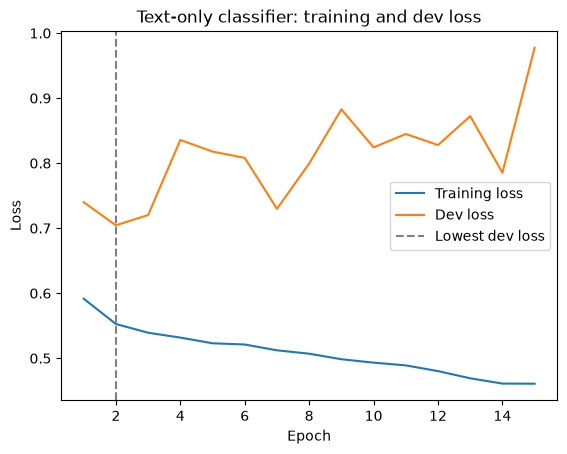

In [21]:
import matplotlib.pyplot as plt

epochs = range(1, len(text_train_losses) + 1)

plt.plot(epochs, text_train_losses, label="Training loss")
plt.plot(epochs, text_dev_losses, label="Dev loss")
plt.axvline(text_best_epoch, color="gray", linestyle="--", label="Lowest dev loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Text-only classifier: training and dev loss")
plt.legend()
plt.savefig("text_loss_curves.png", dpi=200, bbox_inches="tight")
plt.show()

## Part 2: Image-only classification



In [22]:
# Train an image-only classifier and select the lowest dev-loss epoch.
image_model, image_metrics, image_train_losses, image_dev_losses, image_best_epoch = (
    train_classifier(
        X_image["train"], y["train"],
        X_image["dev"], y["dev"]
    )
)

print("\nBest epoch:", image_best_epoch)
print("Image-only dev metrics:", image_metrics)


Epoch  1 | Train loss: 0.6498 | Dev loss: 0.7299
Epoch  2 | Train loss: 0.6375 | Dev loss: 0.7089
Epoch  3 | Train loss: 0.6291 | Dev loss: 0.7553
Epoch  4 | Train loss: 0.6247 | Dev loss: 0.8126
Epoch  5 | Train loss: 0.6231 | Dev loss: 0.8057
Epoch  6 | Train loss: 0.6164 | Dev loss: 0.7591
Epoch  7 | Train loss: 0.6120 | Dev loss: 0.7469
Epoch  8 | Train loss: 0.6044 | Dev loss: 0.7819
Epoch  9 | Train loss: 0.5992 | Dev loss: 0.8373
Epoch 10 | Train loss: 0.5962 | Dev loss: 0.7660
Epoch 11 | Train loss: 0.5863 | Dev loss: 0.8020
Epoch 12 | Train loss: 0.5762 | Dev loss: 0.7793
Epoch 13 | Train loss: 0.5714 | Dev loss: 0.8469
Epoch 14 | Train loss: 0.5646 | Dev loss: 0.8723
Epoch 15 | Train loss: 0.5546 | Dev loss: 0.8137

Best epoch: 2
Image-only dev metrics: {'accuracy': 0.504, 'precision': 0.4918032786885246, 'recall': 0.1214574898785425, 'f1': 0.19480519480519481}


### Image model: training and dev loss


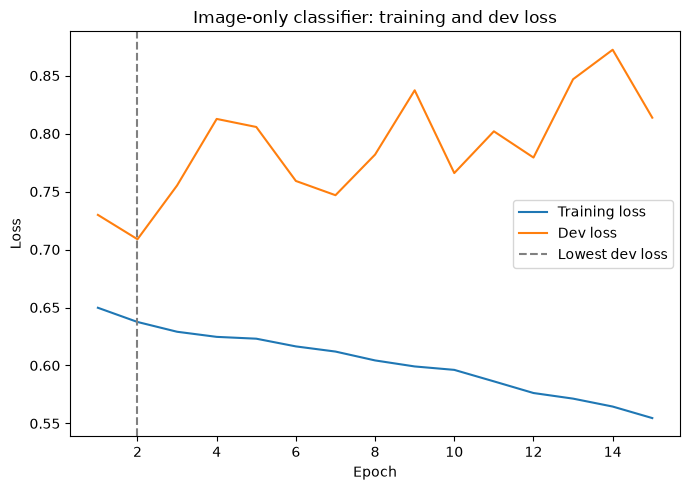

In [23]:
import matplotlib.pyplot as plt

epochs = range(1, len(image_train_losses) + 1)
plt.figure(figsize=(7, 5))
plt.plot(epochs, image_train_losses, label="Training loss")
plt.plot(epochs, image_dev_losses, label="Dev loss")
plt.axvline(image_best_epoch, color="gray", linestyle="--", label="Lowest dev loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Image-only classifier: training and dev loss")
plt.legend()
plt.tight_layout()
plt.savefig("image_loss_curves.png", dpi=200, bbox_inches="tight")
plt.show()


In [24]:
import os

# SAVE_DIR is defined when the saved embeddings are loaded in section 6.
image_model_path = os.path.join(SAVE_DIR, "image_classifier.pt")
torch.save(image_model.state_dict(), image_model_path)
print("Saved image classifier weights to:", image_model_path)


Saved image classifier weights to: lab3_embeddings\image_classifier.pt


## Part 3: Multimodal fusion


In [25]:
# Check that each split contains one text vector and one image vector per label.
for split in ("train", "dev"):
    assert len(X_text[split]) == len(X_image[split]) == len(y[split])

early_train_X = torch.cat((X_text["train"], X_image["train"]), dim=1)
early_dev_X = torch.cat((X_text["dev"], X_image["dev"]), dim=1)
print("Early-fusion shapes:", early_train_X.shape, early_dev_X.shape)

early_model, early_metrics, early_train_losses, early_dev_losses, early_best_epoch = (
    train_classifier(early_train_X, y["train"], early_dev_X, y["dev"])
)
print("\nEarly-fusion best epoch:", early_best_epoch)
print("Early-fusion dev metrics:", early_metrics)


Early-fusion shapes: torch.Size([8500, 1280]) torch.Size([500, 1280])
Epoch  1 | Train loss: 0.5940 | Dev loss: 0.8279
Epoch  2 | Train loss: 0.5489 | Dev loss: 0.7723
Epoch  3 | Train loss: 0.5419 | Dev loss: 0.8169
Epoch  4 | Train loss: 0.5277 | Dev loss: 0.6838
Epoch  5 | Train loss: 0.5131 | Dev loss: 0.8415
Epoch  6 | Train loss: 0.5009 | Dev loss: 0.8306
Epoch  7 | Train loss: 0.4932 | Dev loss: 0.7982
Epoch  8 | Train loss: 0.4875 | Dev loss: 1.0214
Epoch  9 | Train loss: 0.4730 | Dev loss: 0.7217
Epoch 10 | Train loss: 0.4607 | Dev loss: 0.7972
Epoch 11 | Train loss: 0.4496 | Dev loss: 0.8885
Epoch 12 | Train loss: 0.4443 | Dev loss: 0.8222
Epoch 13 | Train loss: 0.4205 | Dev loss: 0.7846
Epoch 14 | Train loss: 0.4066 | Dev loss: 0.8130
Epoch 15 | Train loss: 0.3986 | Dev loss: 0.8905

Early-fusion best epoch: 4
Early-fusion dev metrics: {'accuracy': 0.594, 'precision': 0.6047619047619047, 'recall': 0.5141700404858299, 'f1': 0.5557986870897156}


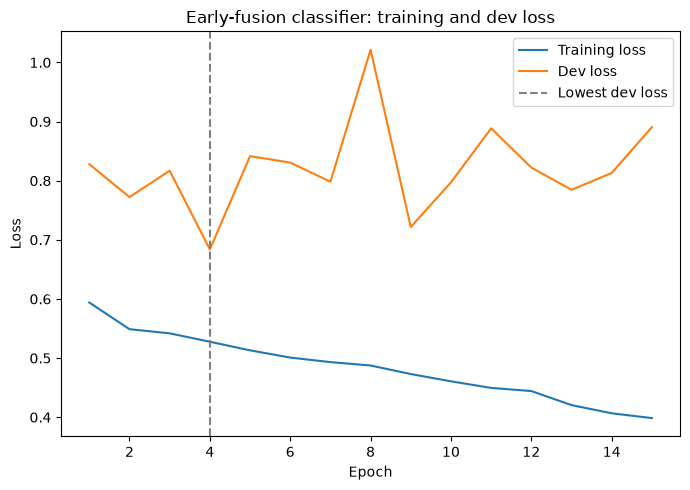

In [26]:
# Plot and save the early-fusion loss curves.
import matplotlib.pyplot as plt

epochs = range(1, len(early_train_losses) + 1)
plt.figure(figsize=(7, 5))
plt.plot(epochs, early_train_losses, label="Training loss")
plt.plot(epochs, early_dev_losses, label="Dev loss")
plt.axvline(early_best_epoch, color="gray", linestyle="--", label="Lowest dev loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Early-fusion classifier: training and dev loss")
plt.legend()
plt.tight_layout()
plt.savefig("early_fusion_loss_curves.png", dpi=200, bbox_inches="tight")
plt.show()


### 3.2 Simple late fusion

In [27]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_probabilities(labels, probabilities):
    """Report metrics at a fixed 0.5 probability threshold."""
    labels = labels.detach().cpu().numpy()
    predictions = (probabilities.detach().cpu().numpy() >= 0.5).astype(int)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1": f1_score(labels, predictions, zero_division=0),
    }

text_model.eval()
image_model.eval()
with torch.no_grad():
    dev_text_probs = torch.sigmoid(text_model(X_text["dev"].float())).squeeze(1)
    dev_image_probs = torch.sigmoid(image_model(X_image["dev"].float())).squeeze(1)

late_probs = 0.5 * dev_text_probs + 0.5 * dev_image_probs
late_metrics = evaluate_probabilities(y["dev"], late_probs)
print("Equal-weight late-fusion dev metrics:", late_metrics)


Equal-weight late-fusion dev metrics: {'accuracy': 0.562, 'precision': 0.6228070175438597, 'recall': 0.2874493927125506, 'f1': 0.39335180055401664}


### 3.3 ARI 510 design change: weighted late fusion

In [28]:
weight_results = []
for i in range(1, 10):
    text_weight = i / 10
    weighted_probs = text_weight * dev_text_probs + (1 - text_weight) * dev_image_probs
    scores = evaluate_probabilities(y["dev"], weighted_probs)
    weight_results.append({"text_weight": text_weight, "image_weight": 1 - text_weight, **scores})

weight_table = pd.DataFrame(weight_results)
display(weight_table.round(4))

# Select on dev F1; if there is a tie, prefer the weight nearest equal fusion.
best_weight_result = max(weight_results, key=lambda row: (row["f1"], -abs(row["text_weight"] - 0.5)))
best_text_weight = best_weight_result["text_weight"]
weighted_metrics = {metric: best_weight_result[metric] for metric in ("accuracy", "precision", "recall", "f1")}
print("Selected text weight:", best_text_weight)
print("Selected image weight:", round(1 - best_text_weight, 1))
print("Weighted late-fusion dev metrics:", weighted_metrics)


,text_weight,image_weight,accuracy,precision,recall,f1
0,0.1,0.9,0.524,0.5882,0.1215,0.2013
1,0.2,0.8,0.536,0.6531,0.1296,0.2162
2,0.3,0.7,0.548,0.6400,0.1943,0.2981
3,0.4,0.6,0.564,0.6526,0.2510,0.3626
4,0.5,0.5,0.562,0.6228,0.2874,0.3934
5,0.6,0.4,0.570,0.6250,0.3239,0.4267
6,0.7,0.3,0.574,0.6232,0.3482,0.4468
7,0.8,0.2,0.574,0.6181,0.3603,0.4552
8,0.9,0.1,0.572,0.6093,0.3725,0.4623


Selected text weight: 0.9
Selected image weight: 0.1
Weighted late-fusion dev metrics: {'accuracy': 0.572, 'precision': 0.609271523178808, 'recall': 0.3724696356275304, 'f1': 0.4623115577889447}


### 3.4 Compare development results and save the selected models

In [29]:
comparison = pd.DataFrame.from_dict({
    "Always not hateful": evaluate_probabilities(y["dev"], torch.zeros_like(y["dev"], dtype=torch.float)),
    "Text only": text_metrics,
    "Image only": image_metrics,
    "Early fusion": early_metrics,
    "Equal-weight late fusion": late_metrics,
    "Weighted late fusion": weighted_metrics,
}, orient="index")
comparison.index.name = "Model"
display(comparison.round(4))


,accuracy,precision,recall,f1
Model,,,,
Always not hateful,0.506,0.0000,0.0000,0.0000
Text only,0.570,0.6026,0.3806,0.4665
Image only,0.504,0.4918,0.1215,0.1948
Early fusion,0.594,0.6048,0.5142,0.5558
Equal-weight late fusion,0.562,0.6228,0.2874,0.3934
Weighted late fusion,0.572,0.6093,0.3725,0.4623


In [30]:
import os
import json

# Save the selected models and chosen weight for the later test comparison.
os.makedirs(SAVE_DIR, exist_ok=True)
torch.save(text_model.state_dict(), os.path.join(SAVE_DIR, "text_classifier.pt"))
torch.save(image_model.state_dict(), os.path.join(SAVE_DIR, "image_classifier.pt"))
torch.save(early_model.state_dict(), os.path.join(SAVE_DIR, "early_fusion_classifier.pt"))
with open(os.path.join(SAVE_DIR, "fusion_settings.json"), "w", encoding="utf-8") as file:
    json.dump({"text_weight": best_text_weight, "threshold": 0.5, "selection_metric": "dev_f1"}, file, indent=2)
print("Saved selected model weights and fusion settings in", SAVE_DIR)


Saved selected model weights and fusion settings in lab3_embeddings


## Part 4: Final test comparison


In [31]:
# Use the saved final comparison when present. This avoids rerunning the test evaluation.
from pathlib import Path
import json
import hashlib
import pandas as pd

result_path = Path("lab3_embeddings/final_test_results.json")
if result_path.exists():
    print("Loading the saved final test evaluation; no model is evaluated again.")
else:
    from pathlib import Path
    import hashlib
    import json
    import torch
    import pandas as pd
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

    # Run from the notebook directory after the development choices are fixed.
    base = Path('lab3_embeddings')
    result_path = base / 'final_test_results.json'
    if result_path.exists():
        raise RuntimeError(f'Final test results already exist at {result_path}; inspect them instead of evaluating again.')

    settings = json.loads((base / 'fusion_settings.json').read_text(encoding='utf-8'))
    assert settings['text_weight'] == 0.9 and settings['threshold'] == 0.5

    def load_model(input_dim, filename):
        model = torch.nn.Sequential(
            torch.nn.Linear(input_dim, 128), torch.nn.ReLU(), torch.nn.Linear(128, 1)
        )
        model.load_state_dict(torch.load(base / filename, map_location='cpu', weights_only=True))
        return model.eval()

    text_model = load_model(768, 'text_classifier.pt')
    image_model = load_model(512, 'image_classifier.pt')
    early_model = load_model(1280, 'early_fusion_classifier.pt')
    text_X = torch.load(base / 'test_text_all.pt', map_location='cpu', weights_only=True).float()
    image_X = torch.load(base / 'test_image_all.pt', map_location='cpu', weights_only=True).float()
    labels = torch.tensor(pd.read_csv(base / 'test_meta_all.csv')['label'].values)
    assert text_X.shape == (1000, 768) and image_X.shape == (1000, 512) and labels.shape == (1000,)

    with torch.no_grad():
        p_text = torch.sigmoid(text_model(text_X)).squeeze(1)
        p_image = torch.sigmoid(image_model(image_X)).squeeze(1)
        p_early = torch.sigmoid(early_model(torch.cat((text_X, image_X), dim=1))).squeeze(1)

    probabilities = {
        'Always not hateful': torch.zeros_like(p_text),
        'Text only': p_text,
        'Image only': p_image,
        'Early fusion': p_early,
        'Equal-weight late fusion': 0.5 * p_text + 0.5 * p_image,
        'Weighted late fusion': settings['text_weight'] * p_text + (1 - settings['text_weight']) * p_image,
    }
    rows = {}
    for name, probs in probabilities.items():
        predictions = (probs >= settings['threshold']).int()
        rows[name] = {
            'accuracy': float(accuracy_score(labels, predictions)),
            'precision': float(precision_score(labels, predictions, zero_division=0)),
            'recall': float(recall_score(labels, predictions, zero_division=0)),
            'f1': float(f1_score(labels, predictions, zero_division=0)),
        }

    record = {
        'description': 'Final test evaluation of fixed checkpoints and dev-selected fusion weight.',
        'sample_count': len(labels),
        'settings': settings,
        'checkpoint_sha256': {name: hashlib.sha256((base / name).read_bytes()).hexdigest() for name in ('text_classifier.pt', 'image_classifier.pt', 'early_fusion_classifier.pt')},
        'results': rows,
    }
    with result_path.open('x', encoding='utf-8') as f:
        json.dump(record, f, indent=2)
    print('Final test results (fixed models; threshold 0.5):')
    print(pd.DataFrame.from_dict(rows, orient='index').round(4).to_string())
    print('Saved:', result_path)

# Check that the saved report still corresponds to the checkpoint files.
with result_path.open(encoding="utf-8") as file:
    final_test_record = json.load(file)
for filename, expected_hash in final_test_record["checkpoint_sha256"].items():
    actual_hash = hashlib.sha256((result_path.parent / filename).read_bytes()).hexdigest()
    if actual_hash != expected_hash:
        print(f"Warning: {filename} changed after the final test evaluation.")

final_test_comparison = pd.DataFrame.from_dict(final_test_record["results"], orient="index")
final_test_comparison.index.name = "Model"
display(final_test_comparison.round(4))


Loading the saved final test evaluation; no model is evaluated again.


,accuracy,precision,recall,f1
Model,,,,
Always not hateful,0.510,0.0000,0.0000,0.0000
Text only,0.617,0.6533,0.4653,0.5435
Image only,0.523,0.5520,0.1408,0.2244
Early fusion,0.631,0.6312,0.5939,0.6120
Equal-weight late fusion,0.601,0.6888,0.3388,0.4542
Weighted late fusion,0.617,0.6569,0.4571,0.5391
